# Notebook 07 — Deep Learning Sequence Models (LSTM and GRU)

**Project:** Isolated Word-Level American Sign Language Recognition using WLASL  
**Dataset:** WLASL-100 · **Evaluation:** frozen signer-independent split  
**Feature version:** `wlasl100_landmark_features_v2`

## Research question

Does explicitly modelling the temporal evolution of landmark sequences improve isolated sign recognition relative to the classical models from Notebook 06?

This notebook trains two deliberately modest sequence baselines:

- **LSTM:** two recurrent layers with 128 hidden units.
- **GRU:** the same hidden width, depth, projection and classification head.

The models receive the same examples, temporal representation, optimizer, training budget and validation-based checkpoint rule. Test data is reserved for the final evaluation.

> **Execution contract:** run this notebook from the existing `sign-language-recognition` project after Notebooks 01–06 have completed. It reads Notebook 05's v2 feature files and frozen split CSVs. It writes only to the new `data/models/deep_learning/v1/` and `data/reports/deep_learning/v1/` directories.

## 1. Methodological decisions

### Input construction and missingness

Notebook 05 stores `relative_coordinates` with shape `(32, 225)`. These 225 channels are the pose, left-hand and right-hand XYZ coordinates in their respective reference frames. The file also stores body-relative wrist trajectories, their velocity and acceleration, detection masks, confidence values and a coordinate-missingness mask.

The model input is constructed by concatenating:

| Component | Channels |
|---|---:|
| Relative coordinates | 225 |
| Body-relative wrist position | 6 |
| Body-relative wrist velocity | 6 |
| Body-relative wrist acceleration | 6 |
| Hand confidence | 2 |
| Continuous-channel missingness indicators | 245 |
| Detection / confidence-availability masks | 5 |
| **Total** | **495** |

This is a sequence of 32 time steps, not a flattened static vector. The original 225 coordinate channels remain intact. The additional channels preserve information that would otherwise be lost when missing coordinates or unavailable derived motion values are imputed. The stored 225-channel coordinate-missingness mask is merged into the corresponding coordinate indicators.

The general `velocity` and `acceleration` arrays are not concatenated again: the recurrent model can learn temporal changes from the coordinate sequence, while the explicitly corrected body-relative wrist motion features retain global hand movement relative to the torso. This avoids an unnecessarily redundant input.

NaNs in continuous channels are replaced using **per-channel medians fitted only on training videos**. Missingness is retained as explicit input channels. No scaler is fitted: Notebook 05's relative-coordinate representation is used as produced, avoiding an unjustified second normalization.

### Model selection and evaluation

- Early stopping monitors validation macro-F1 over the fixed 100 training labels.
- Validation is used for checkpoint selection and learning-rate scheduling only.
- The test set is not used for training, tuning, early stopping or architecture selection.
- Accuracy and top-5 use every test example. Macro-F1 over the fixed 100 labels assigns zero to classes with no test support; macro-F1 over represented test labels is reported separately.
- No class weights are applied by default. The training distribution is inspected and recorded; class weighting is not assumed to be beneficial.

The two architectures are compared as controlled baselines, not as a broad hyperparameter search.

## 2. Imports, reproducibility and project paths

The project root is discovered using the official WLASL metadata marker. If discovery fails, set `PROJECT_DIR` explicitly. The notebook does not install packages or modify any upstream artifacts.

In [1]:
from pathlib import Path
import json
import os
import platform
import random
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sklearn
from sklearn.metrics import (
    accuracy_score, f1_score, precision_recall_fscore_support,
    classification_report, confusion_matrix
)

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 165
PROJECT_DIR = None  # Set to Path("/absolute/path/to/sign-language-recognition") if needed.
FEATURE_VERSION = "wlasl100_landmark_features_v2"
EXPECTED_SPLIT_COUNTS = {"train": 535, "val": 171, "test": 317}
EXPECTED_CLASSES = 100

def find_project_root(override=None):
    candidates = []
    if override is not None:
        candidates.append(Path(override).expanduser())
    candidates.extend([Path.home() / "sign-language-recognition", Path.cwd(), *Path.cwd().parents])
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if (candidate / "WLASL" / "start_kit" / "WLASL_v0.3.json").is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Set PROJECT_DIR to the folder containing "
        "WLASL/start_kit/WLASL_v0.3.json and data/."
    )

ROOT = find_project_root(PROJECT_DIR)
DATA = ROOT / "data" / "processed" / "WLASL100"
FEATURES = DATA / "features" / "v2"
TEMPORAL_DIR = FEATURES / "temporal"
FEATURE_MANIFEST_PATH = FEATURES / "manifests" / "feature_manifest.csv"

MODEL_DIR = ROOT / "data" / "models" / "deep_learning" / "v1"
REPORT_DIR = ROOT / "data" / "reports" / "deep_learning" / "v1"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    # MPS does not guarantee bitwise determinism for every operation.
    try:
        torch.use_deterministic_algorithms(True, warn_only=True)
    except Exception:
        pass

seed_everything()

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print(f"Project root: {ROOT}")
print(f"Temporal features: {TEMPORAL_DIR}")
print(f"Device: {DEVICE}")
print(f"Python: {platform.python_version()} | PyTorch: {torch.__version__} | scikit-learn: {sklearn.__version__}")

Project root: /Users/sahilchauhan/sign-language-recognition
Temporal features: /Users/sahilchauhan/sign-language-recognition/data/processed/WLASL100/features/v2/temporal
Device: mps
Python: 3.12.15 | PyTorch: 2.14.1 | scikit-learn: 1.9.1


## 3. Load and audit the frozen splits

The split CSVs are the source of truth for signer assignments. The feature manifest supplies the usable temporal-file paths. Every feature row is cross-checked against its frozen `video_id`, gloss, signer and split. We assert the expected usable-video counts, all 100 training classes, and zero signer overlap before training.

In [2]:
def load_frozen_metadata():
    pieces = []
    for split in ("train", "val", "test"):
        path = DATA / f"{split}_metadata.csv"
        if not path.is_file():
            raise FileNotFoundError(f"Missing frozen split file: {path}")
        frame = pd.read_csv(path, dtype={"video_id": str, "signer_id": str})
        required = {"video_id", "gloss", "signer_id"}
        missing = required - set(frame.columns)
        if missing:
            raise ValueError(f"{path.name} is missing columns: {sorted(missing)}")
        frame["video_id"] = frame["video_id"].astype(str).str.strip()
        frame["signer_id"] = frame["signer_id"].astype(str).str.strip()
        frame["gloss"] = frame["gloss"].astype(str).str.strip()
        frame["experimental_split"] = split
        pieces.append(frame[["video_id", "gloss", "signer_id", "experimental_split"]])
    frozen = pd.concat(pieces, ignore_index=True)
    if frozen["video_id"].duplicated().any():
        raise AssertionError("A video_id occurs in more than one frozen split.")
    return frozen

frozen = load_frozen_metadata()
signer_sets = {
    split: set(frozen.loc[frozen.experimental_split.eq(split), "signer_id"])
    for split in ("train", "val", "test")
}
overlaps = {
    f"{a}-{b}": sorted(signer_sets[a] & signer_sets[b])
    for a, b in (("train", "val"), ("train", "test"), ("val", "test"))
}
assert all(len(v) == 0 for v in overlaps.values()), f"Signer leakage: {overlaps}"

if not FEATURE_MANIFEST_PATH.is_file():
    raise FileNotFoundError(f"Missing Notebook 05 feature manifest: {FEATURE_MANIFEST_PATH}")
feature_manifest = pd.read_csv(FEATURE_MANIFEST_PATH, dtype={"video_id": str, "signer_id": str})
required_manifest = {"video_id", "gloss", "signer_id", "experimental_split", "temporal_path", "status"}
if required_manifest - set(feature_manifest.columns):
    raise ValueError(f"Feature manifest lacks: {sorted(required_manifest - set(feature_manifest.columns))}")

usable = feature_manifest.loc[feature_manifest.status.eq("processed")].copy()
usable["video_id"] = usable.video_id.astype(str).str.strip()
usable["signer_id"] = usable.signer_id.astype(str).str.strip()
usable["gloss"] = usable.gloss.astype(str).str.strip()
usable["experimental_split"] = usable.experimental_split.astype(str).str.strip()
if usable.video_id.duplicated().any():
    raise AssertionError("Duplicate video IDs in processed feature manifest.")

joined = usable.merge(
    frozen, on="video_id", how="left", suffixes=("_feature", "_frozen"),
    validate="one_to_one", indicator=True
)
assert joined["_merge"].eq("both").all(), "Feature rows include IDs outside the frozen split."
for col in ("gloss", "signer_id", "experimental_split"):
    assert (
        joined[f"{col}_feature"].astype(str).to_numpy()
        == joined[f"{col}_frozen"].astype(str).to_numpy()
    ).all(), f"Feature manifest disagrees with frozen metadata for {col}."

split_counts = usable.experimental_split.value_counts().to_dict()
assert split_counts == EXPECTED_SPLIT_COUNTS, (
    f"Usable split counts changed: expected {EXPECTED_SPLIT_COUNTS}, got {split_counts}"
)

class_names = np.array(sorted(usable.loc[usable.experimental_split.eq("train"), "gloss"].unique()))
assert len(class_names) == EXPECTED_CLASSES, f"Expected 100 training classes, found {len(class_names)}"
class_to_idx = {name: i for i, name in enumerate(class_names)}
assert set(usable.gloss).issubset(set(class_names)), "Validation/test contains a label absent from training."

for split in ("train", "val", "test"):
    assert len(set(usable.loc[usable.experimental_split.eq(split), "signer_id"])) > 0

split_audit = pd.DataFrame({
    "split": ["train", "val", "test"],
    "usable_videos": [split_counts[s] for s in ("train", "val", "test")],
    "metadata_signers": [len(signer_sets[s]) for s in ("train", "val", "test")],
    "usable_signers": [
        usable.loc[usable.experimental_split.eq(s), "signer_id"].nunique()
        for s in ("train", "val", "test")
    ],
    "represented_classes": [
        usable.loc[usable.experimental_split.eq(s), "gloss"].nunique()
        for s in ("train", "val", "test")
    ],
})
display(split_audit)
print("Signer intersections:", {k: len(v) for k, v in overlaps.items()})
print("Fixed class order:", class_names.tolist())

,split,usable_videos,metadata_signers,usable_signers,represented_classes
0,train,535,62,31,100
1,val,171,15,7,91
2,test,317,20,12,98


Signer intersections: {'train-val': 0, 'train-test': 0, 'val-test': 0}
Fixed class order: ['accident', 'africa', 'all', 'apple', 'basketball', 'bed', 'before', 'bird', 'birthday', 'black', 'blue', 'book', 'bowling', 'brown', 'but', 'can', 'candy', 'chair', 'change', 'cheat', 'city', 'clothes', 'color', 'computer', 'cook', 'cool', 'corn', 'cousin', 'cow', 'dance', 'dark', 'deaf', 'decide', 'doctor', 'dog', 'drink', 'eat', 'enjoy', 'family', 'fine', 'finish', 'fish', 'forget', 'full', 'give', 'go', 'graduate', 'hat', 'hearing', 'help', 'hot', 'how', 'jacket', 'kiss', 'language', 'last', 'later', 'letter', 'like', 'man', 'many', 'medicine', 'meet', 'mother', 'need', 'no', 'now', 'orange', 'paint', 'paper', 'pink', 'pizza', 'play', 'pull', 'purple', 'right', 'same', 'school', 'secretary', 'shirt', 'short', 'son', 'study', 'table', 'tall', 'tell', 'thanksgiving', 'thin', 'thursday', 'time', 'walk', 'want', 'what', 'white', 'who', 'woman', 'work', 'wrong', 'year', 'yes']


## 4. Inspect the actual temporal NPZ schema

Before loading the full dataset, inspect one real feature file and validate the keys, shapes, dtypes and feature-version marker. This is deliberately strict: a stale or incompatible feature directory should fail loudly rather than silently train a different experiment.

In [3]:
sample_row = usable.iloc[0]
sample_path = Path(sample_row.temporal_path)
if not sample_path.is_file():
    sample_path = TEMPORAL_DIR / f"{sample_row.video_id}.npz"
if not sample_path.is_file():
    raise FileNotFoundError(f"Temporal NPZ not found for video {sample_row.video_id}: {sample_path}")

with np.load(sample_path, allow_pickle=False) as z:
    temporal_schema = {
        key: {"shape": list(z[key].shape), "dtype": str(z[key].dtype)}
        for key in z.files
    }
    required_npz_keys = {
        "relative_coordinates", "hand_to_body", "hand_body_velocity",
        "hand_body_acceleration", "detection_masks", "hand_confidence",
        "coordinate_missing_mask", "video_id", "feature_version"
    }
    assert required_npz_keys.issubset(z.files), (
        f"Temporal NPZ missing keys: {sorted(required_npz_keys - set(z.files))}"
    )
    assert str(z["feature_version"].item()) == FEATURE_VERSION
    assert str(z["video_id"].item()) == str(sample_row.video_id)

display(pd.DataFrame([
    {"array": k, **v} for k, v in temporal_schema.items()
]))

,array,shape,dtype
0,raw_coordinates,"[32, 225]",float32
1,relative_coordinates,"[32, 225]",float32
2,hand_to_body,"[32, 6]",float32
3,velocity,"[32, 225]",float32
4,acceleration,"[32, 225]",float32
5,hand_body_velocity,"[32, 6]",float32
6,hand_body_acceleration,"[32, 6]",float32
7,detection_masks,"[32, 5]",uint8
8,hand_confidence,"[32, 2]",float32
9,coordinate_missing_mask,"[32, 225]",uint8


## 5. Build a sequence tensor while preserving missingness

The model sees `(time, channels)` for each video. Continuous channels are assembled separately from binary masks so that imputation never destroys the missingness signal.

For each continuous channel, the median is fitted over **training videos and their 32 time steps only**. A channel that is entirely missing in training receives a neutral zero fill and is flagged in the saved preprocessing metadata. Validation and test data only use these frozen medians.

In [4]:
N_STEPS = 32
N_COORD = 225
N_CONTINUOUS = 245
N_MASK = 250
INPUT_DIM = N_CONTINUOUS + N_MASK  # 495

def load_one_sequence(row):
    path = Path(row.temporal_path)
    if not path.is_file():
        path = TEMPORAL_DIR / f"{row.video_id}.npz"
    if not path.is_file():
        raise FileNotFoundError(f"Missing temporal NPZ: {path}")

    with np.load(path, allow_pickle=False) as z:
        if str(z["feature_version"].item()) != FEATURE_VERSION:
            raise ValueError(f"Feature-version mismatch in {path.name}")
        if str(z["video_id"].item()) != str(row.video_id):
            raise ValueError(f"video_id mismatch in {path.name}")

        relative = np.asarray(z["relative_coordinates"], dtype=np.float32)
        hand_body = np.asarray(z["hand_to_body"], dtype=np.float32)
        hb_velocity = np.asarray(z["hand_body_velocity"], dtype=np.float32)
        hb_acceleration = np.asarray(z["hand_body_acceleration"], dtype=np.float32)
        confidence = np.asarray(z["hand_confidence"], dtype=np.float32)
        detection = np.asarray(z["detection_masks"], dtype=np.float32)
        stored_missing = np.asarray(z["coordinate_missing_mask"], dtype=np.float32)

    expected = {
        "relative_coordinates": (N_STEPS, N_COORD),
        "hand_to_body": (N_STEPS, 6),
        "hand_body_velocity": (N_STEPS, 6),
        "hand_body_acceleration": (N_STEPS, 6),
        "hand_confidence": (N_STEPS, 2),
        "detection_masks": (N_STEPS, 5),
        "coordinate_missing_mask": (N_STEPS, N_COORD),
    }
    actual = {
        "relative_coordinates": relative.shape,
        "hand_to_body": hand_body.shape,
        "hand_body_velocity": hb_velocity.shape,
        "hand_body_acceleration": hb_acceleration.shape,
        "hand_confidence": confidence.shape,
        "detection_masks": detection.shape,
        "coordinate_missing_mask": stored_missing.shape,
    }
    assert actual == expected, f"Unexpected sequence shapes for {row.video_id}: {actual}"
    for name, arr in {
        "relative_coordinates": relative, "hand_to_body": hand_body,
        "hand_body_velocity": hb_velocity, "hand_body_acceleration": hb_acceleration,
        "hand_confidence": confidence, "detection_masks": detection,
        "coordinate_missing_mask": stored_missing,
    }.items():
        if np.isinf(arr).any():
            raise ValueError(f"Infinite values in {name} for {row.video_id}")

    # Continuous channels: 225 + 6 + 6 + 6 + 2 = 245.
    continuous = np.concatenate(
        [relative, hand_body, hb_velocity, hb_acceleration, confidence], axis=1
    ).astype(np.float32)

    # Preserve missingness for every continuous channel, including the first
    # frames of finite-difference features. Merge Notebook 05's explicit raw-coordinate
    # mask into the corresponding 225 relative-coordinate indicators.
    continuous_missing = (~np.isfinite(continuous)).astype(np.float32)
    continuous_missing[:, :N_COORD] = np.maximum(
        continuous_missing[:, :N_COORD], stored_missing
    )
    masks = np.concatenate([continuous_missing, detection], axis=1).astype(np.float32)

    sequence = np.concatenate([continuous, masks], axis=1)
    assert sequence.shape == (N_STEPS, INPUT_DIM)
    return sequence

def load_split(split):
    rows = usable.loc[usable.experimental_split.eq(split)].sort_values(
        "video_id", kind="stable"
    )
    sequences, labels, ids, signers = [], [], [], []
    for row in rows.itertuples(index=False):
        sequences.append(load_one_sequence(row))
        labels.append(class_to_idx[row.gloss])
        ids.append(str(row.video_id))
        signers.append(str(row.signer_id))
    X = np.stack(sequences).astype(np.float32)
    y = np.asarray(labels, dtype=np.int64)
    assert X.shape == (len(rows), N_STEPS, INPUT_DIM)
    assert y.shape == (len(rows),)
    assert np.all((0 <= y) & (y < len(class_names)))
    return X, y, np.asarray(ids), np.asarray(signers)

X_train_raw, y_train, id_train, signer_train = load_split("train")
X_val_raw, y_val, id_val, signer_val = load_split("val")
X_test_raw, y_test, id_test, signer_test = load_split("test")

assert X_train_raw.shape[0] == 535
assert X_val_raw.shape[0] == 171
assert X_test_raw.shape[0] == 317
assert len(set(signer_train) & set(signer_val)) == 0
assert len(set(signer_train) & set(signer_test)) == 0
assert len(set(signer_val) & set(signer_test)) == 0

print("Raw sequence tensors:")
print("Train:", X_train_raw.shape, "Validation:", X_val_raw.shape, "Test:", X_test_raw.shape)
print("Input channels:", INPUT_DIM, "(continuous:", N_CONTINUOUS, "+ masks:", N_MASK, ")")

Raw sequence tensors:
Train: (535, 32, 495) Validation: (171, 32, 495) Test: (317, 32, 495)
Input channels: 495 (continuous: 245 + masks: 250 )


## 6. Fit training-only imputation

Only the first 245 channels are continuous. Binary missingness/detection channels remain unchanged. The imputation statistics are estimated from the training partition alone, then applied unchanged to validation and test.

In [5]:
def fit_channel_medians(X_train, n_continuous=N_CONTINUOUS):
    values = X_train[:, :, :n_continuous].reshape(-1, n_continuous)
    medians = np.zeros(n_continuous, dtype=np.float32)
    all_missing = np.zeros(n_continuous, dtype=bool)
    for j in range(n_continuous):
        finite = values[:, j][np.isfinite(values[:, j])]
        if finite.size:
            medians[j] = np.median(finite)
        else:
            medians[j] = 0.0
            all_missing[j] = True
    return medians, all_missing

channel_medians, all_missing_channels = fit_channel_medians(X_train_raw)

def apply_train_imputation(X, medians):
    out = X.copy()
    continuous = out[:, :, :N_CONTINUOUS]
    for j, median in enumerate(medians):
        bad = ~np.isfinite(continuous[:, :, j])
        continuous[:, :, j][bad] = median
    # Mask channels should be finite binary indicators.
    if not np.isfinite(out[:, :, N_CONTINUOUS:]).all():
        raise ValueError("Non-finite values found in mask channels.")
    return out.astype(np.float32)

X_train = apply_train_imputation(X_train_raw, channel_medians)
X_val = apply_train_imputation(X_val_raw, channel_medians)
X_test = apply_train_imputation(X_test_raw, channel_medians)

assert np.isfinite(X_train).all()
assert np.isfinite(X_val).all()
assert np.isfinite(X_test).all()
np.savez_compressed(
    REPORT_DIR / "train_only_imputation.npz",
    channel_medians=channel_medians,
    all_missing_training_channels=all_missing_channels,
    continuous_channel_count=np.array(N_CONTINUOUS),
    input_channel_count=np.array(INPUT_DIM),
)
print("All model inputs are finite.")
print("Continuous channels entirely missing in training:", int(all_missing_channels.sum()))
print("Training class-count range:",
      int(pd.Series(y_train).value_counts().min()),
      "to", int(pd.Series(y_train).value_counts().max()))

All model inputs are finite.
Continuous channels entirely missing in training: 0
Training class-count range: 2 to 9


## 7. Model architecture

Both networks use the same input projection, recurrent depth, hidden width, dropout and classifier. The only architectural difference is the recurrent cell.

An LSTM maintains a cell state and uses input, forget and output gates to regulate information flow. A GRU uses update and reset gates and has a simpler state update. Both can represent temporal order and dependencies across the 32 frames.

For a recurrent state \(h_t\), the classifier uses the final layer's final hidden state. The output is **logits**; `CrossEntropyLoss` internally applies the appropriate log-softmax operation.

In [6]:
MODEL_CONFIG = {
    "input_dim": INPUT_DIM,
    "projection_dim": 128,
    "hidden_dim": 128,
    "num_layers": 2,
    "dropout": 0.25,
    "num_classes": len(class_names),
    "bidirectional": False,
}

class LandmarkSequenceClassifier(nn.Module):
    def __init__(self, cell_type, config):
        super().__init__()
        self.cell_type = cell_type.upper()
        self.projection = nn.Sequential(
            nn.Linear(config["input_dim"], config["projection_dim"]),
            nn.ReLU(),
            nn.Dropout(config["dropout"]),
        )
        recurrent = nn.LSTM if self.cell_type == "LSTM" else nn.GRU
        self.recurrent = recurrent(
            input_size=config["projection_dim"],
            hidden_size=config["hidden_dim"],
            num_layers=config["num_layers"],
            batch_first=True,
            dropout=config["dropout"] if config["num_layers"] > 1 else 0.0,
            bidirectional=config["bidirectional"],
        )
        direction_factor = 2 if config["bidirectional"] else 1
        self.classifier = nn.Sequential(
            nn.Dropout(config["dropout"]),
            nn.Linear(config["hidden_dim"] * direction_factor, config["num_classes"]),
        )

    def forward(self, x):
        x = self.projection(x)
        _, state = self.recurrent(x)
        hidden = state[0] if self.cell_type == "LSTM" else state
        final_hidden = hidden[-1]
        return self.classifier(final_hidden)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

for cell in ("LSTM", "GRU"):
    model = LandmarkSequenceClassifier(cell, MODEL_CONFIG)
    dummy = torch.zeros(4, N_STEPS, INPUT_DIM)
    logits = model(dummy)
    assert logits.shape == (4, len(class_names))
    assert torch.isfinite(logits).all()
    print(f"{cell}: {count_parameters(model):,} trainable parameters")

LSTM: 340,580 trainable parameters
GRU: 274,532 trainable parameters


## 8. Training protocol

- Optimizer: AdamW.
- Loss: unweighted cross-entropy (the class distribution is recorded above).
- Batch size: 32.
- Maximum epochs: 100.
- Gradient clipping: global norm 1.0.
- Scheduler: `ReduceLROnPlateau` on validation macro-F1.
- Early stopping: patience 12 epochs, based on validation fixed-100 macro-F1.
- Checkpoint: highest validation macro-F1; validation loss breaks exact ties.

Training and validation metrics are recomputed in evaluation mode after every epoch so that the curves are comparable. MPS timing is synchronized before and after benchmark intervals.

In [7]:
TRAIN_CONFIG = {
    "seed": SEED,
    "batch_size": 32,
    "max_epochs": 100,
    "early_stopping_patience": 12,
    "min_delta": 1e-4,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "gradient_clip_norm": 1.0,
    "scheduler_factor": 0.5,
    "scheduler_patience": 4,
    "class_weighting": "none",
    "selection_metric": "validation macro-F1 over fixed training label set (100 labels)",
}

def sync_device():
    if DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "cuda":
        torch.cuda.synchronize()

def make_loader(X, y, batch_size, shuffle):
    dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle,
        num_workers=0, generator=generator, pin_memory=False
    )

train_loader = make_loader(X_train, y_train, TRAIN_CONFIG["batch_size"], True)
train_eval_loader = make_loader(X_train, y_train, TRAIN_CONFIG["batch_size"], False)
val_loader = make_loader(X_val, y_val, TRAIN_CONFIG["batch_size"], False)

def collect_metrics(model, loader, criterion):
    model.eval()
    losses, truths, predictions = [], [], []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            logits = model(xb)
            if not torch.isfinite(logits).all():
                raise FloatingPointError("Non-finite model logits encountered.")
            loss = criterion(logits, yb)
            losses.append(float(loss.item()) * len(yb))
            truths.extend(yb.cpu().numpy().tolist())
            predictions.extend(logits.argmax(dim=1).cpu().numpy().tolist())
    truths = np.asarray(truths, dtype=np.int64)
    predictions = np.asarray(predictions, dtype=np.int64)
    return {
        "loss": float(np.sum(losses) / len(truths)),
        "accuracy": float(accuracy_score(truths, predictions)),
        "macro_f1": float(f1_score(
            truths, predictions, labels=np.arange(len(class_names)),
            average="macro", zero_division=0
        )),
    }

def train_model(cell_type):
    seed_everything(SEED)
    # Recreate the shuffled loader after reseeding so LSTM and GRU see the same batch-order seed.
    model_train_loader = make_loader(X_train, y_train, TRAIN_CONFIG["batch_size"], True)
    model = LandmarkSequenceClassifier(cell_type, MODEL_CONFIG).to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=TRAIN_CONFIG["learning_rate"],
        weight_decay=TRAIN_CONFIG["weight_decay"],
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=TRAIN_CONFIG["scheduler_factor"],
        patience=TRAIN_CONFIG["scheduler_patience"]
    )

    checkpoint_path = MODEL_DIR / f"best_{cell_type.lower()}.pt"
    history = []
    best_f1 = -1.0
    best_val_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0
    start_training = time.perf_counter()

    for epoch in range(1, TRAIN_CONFIG["max_epochs"] + 1):
        model.train()
        batch_loss_sum = 0.0
        seen = 0
        for xb, yb in model_train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            loss = criterion(logits, yb)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite {cell_type} training loss.")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), TRAIN_CONFIG["gradient_clip_norm"])
            optimizer.step()
            batch_loss_sum += float(loss.item()) * len(yb)
            seen += len(yb)

        train_metrics = collect_metrics(model, train_eval_loader, criterion)
        val_metrics = collect_metrics(model, val_loader, criterion)
        scheduler.step(val_metrics["macro_f1"])
        current_lr = float(optimizer.param_groups[0]["lr"])

        row = {
            "epoch": epoch,
            "train_loss": train_metrics["loss"],
            "val_loss": val_metrics["loss"],
            "train_accuracy": train_metrics["accuracy"],
            "val_accuracy": val_metrics["accuracy"],
            "train_macro_f1": train_metrics["macro_f1"],
            "val_macro_f1": val_metrics["macro_f1"],
            "learning_rate": current_lr,
        }
        history.append(row)

        improved = (
            val_metrics["macro_f1"] > best_f1 + TRAIN_CONFIG["min_delta"]
            or (
                abs(val_metrics["macro_f1"] - best_f1) <= TRAIN_CONFIG["min_delta"]
                and val_metrics["loss"] < best_val_loss
            )
        )
        if improved:
            best_f1 = val_metrics["macro_f1"]
            best_val_loss = val_metrics["loss"]
            best_epoch = epoch
            epochs_without_improvement = 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "cell_type": cell_type,
                "model_config": MODEL_CONFIG,
                "train_config": TRAIN_CONFIG,
                "class_names": class_names.tolist(),
                "best_epoch": best_epoch,
                "best_validation_macro_f1": best_f1,
                "best_validation_loss": best_val_loss,
                "seed": SEED,
            }, checkpoint_path)
        else:
            epochs_without_improvement += 1

        if epoch == 1 or epoch % 5 == 0:
            print(
                f"{cell_type} | epoch {epoch:03d} | "
                f"train loss {train_metrics['loss']:.4f} | "
                f"val loss {val_metrics['loss']:.4f} | "
                f"val macro-F1 {val_metrics['macro_f1']:.4f} | "
                f"lr {current_lr:.2e}"
            )

        if epochs_without_improvement >= TRAIN_CONFIG["early_stopping_patience"]:
            print(f"{cell_type}: early stopping at epoch {epoch}.")
            break

    sync_device()
    training_seconds = time.perf_counter() - start_training
    history_df = pd.DataFrame(history)
    history_df.to_csv(REPORT_DIR / f"{cell_type.lower()}_training_history.csv", index=False)

    # Reload the best validation-selected checkpoint before returning.
    checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()
    return {
        "model": model,
        "history": history_df,
        "checkpoint_path": checkpoint_path,
        "best_epoch": best_epoch,
        "best_validation_macro_f1": best_f1,
        "training_seconds": training_seconds,
        "parameters": count_parameters(model),
    }

## 9. Train LSTM and GRU

Both models are trained with the same fixed configuration. The validation set determines each model's best checkpoint independently. No test metrics are computed in this stage.

In [8]:
experiments = {}
for cell_type in ("LSTM", "GRU"):
    print("\n" + "=" * 72)
    print(f"Training {cell_type}")
    print("=" * 72)
    experiments[cell_type] = train_model(cell_type)

training_overview = pd.DataFrame([
    {
        "model": name,
        "best_epoch": result["best_epoch"],
        "best_validation_macro_f1": result["best_validation_macro_f1"],
        "training_seconds": result["training_seconds"],
        "trainable_parameters": result["parameters"],
        "checkpoint": str(result["checkpoint_path"].relative_to(ROOT)),
    }
    for name, result in experiments.items()
])
display(training_overview)
training_overview.to_csv(REPORT_DIR / "training_overview.csv", index=False)


Training LSTM
LSTM | epoch 001 | train loss 4.5952 | val loss 4.6076 | val macro-F1 0.0002 | lr 1.00e-03
LSTM | epoch 005 | train loss 4.1481 | val loss 4.3721 | val macro-F1 0.0007 | lr 1.00e-03
LSTM | epoch 010 | train loss 4.0579 | val loss 4.4065 | val macro-F1 0.0024 | lr 5.00e-04
LSTM | epoch 015 | train loss 3.9998 | val loss 4.4018 | val macro-F1 0.0023 | lr 2.50e-04
LSTM | epoch 020 | train loss 3.9634 | val loss 4.4000 | val macro-F1 0.0036 | lr 1.25e-04
LSTM: early stopping at epoch 20.

Training GRU
GRU | epoch 001 | train loss 4.5836 | val loss 4.6226 | val macro-F1 0.0001 | lr 1.00e-03
GRU | epoch 005 | train loss 4.1450 | val loss 4.3646 | val macro-F1 0.0021 | lr 1.00e-03
GRU | epoch 010 | train loss 3.9786 | val loss 4.3896 | val macro-F1 0.0030 | lr 1.00e-03
GRU | epoch 015 | train loss 3.7743 | val loss 4.3780 | val macro-F1 0.0045 | lr 1.00e-03
GRU | epoch 020 | train loss 3.5724 | val loss 4.4766 | val macro-F1 0.0011 | lr 1.00e-03
GRU | epoch 025 | train loss 3.3

,model,best_epoch,best_validation_macro_f1,training_seconds,trainable_parameters,checkpoint
0,LSTM,8,0.003737,12.006231,340580,data/models/deep_learning/v1/best_lstm.pt
1,GRU,32,0.029774,34.610389,274532,data/models/deep_learning/v1/best_gru.pt


## 10. Training diagnostics

The following plots are based only on training and validation data. The validation macro-F1 curve also shows the metric used for checkpoint selection.

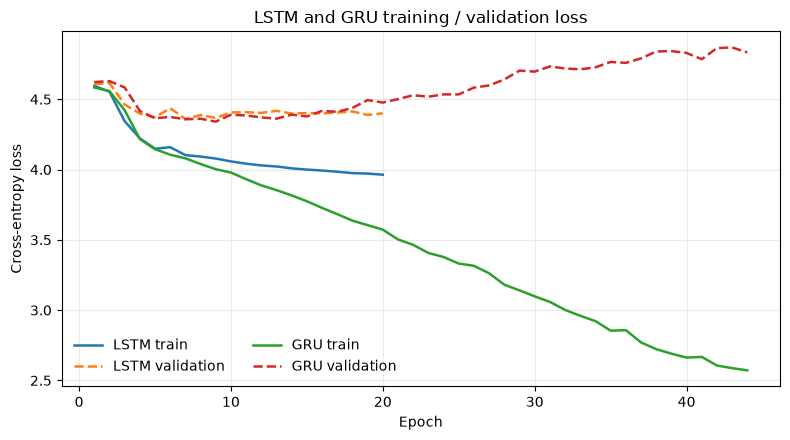

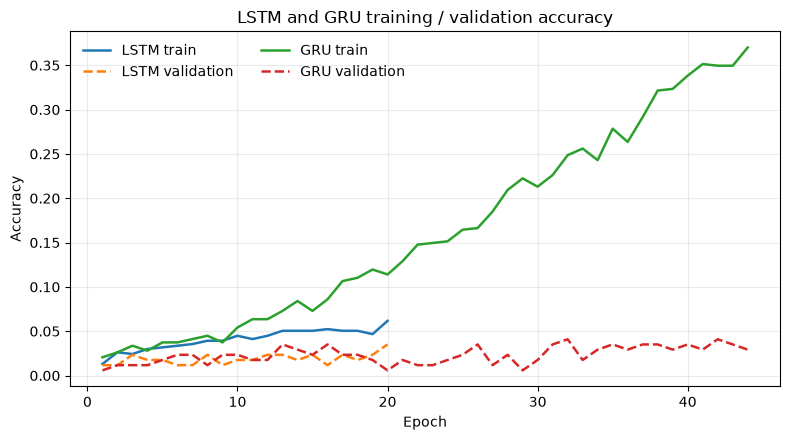

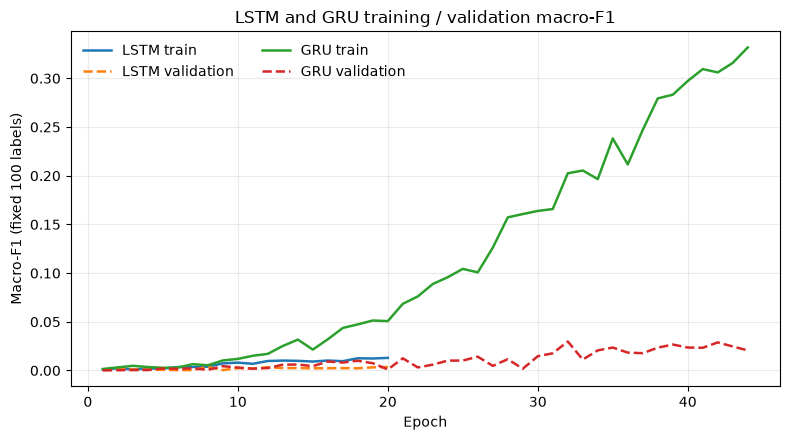

In [9]:
def plot_training_histories(experiments, metric, ylabel, title, filename):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for name, result in experiments.items():
        hist = result["history"]
        ax.plot(hist["epoch"], hist[f"train_{metric}"], label=f"{name} train", linewidth=1.8)
        ax.plot(hist["epoch"], hist[f"val_{metric}"], label=f"{name} validation",
                linewidth=1.8, linestyle="--")
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(ncol=2, frameon=False)
    fig.tight_layout()
    fig.savefig(REPORT_DIR / filename, dpi=180, bbox_inches="tight")
    plt.show()

plot_training_histories(experiments, "loss", "Cross-entropy loss",
                        "LSTM and GRU training / validation loss",
                        "training_validation_loss.png")
plot_training_histories(experiments, "accuracy", "Accuracy",
                        "LSTM and GRU training / validation accuracy",
                        "training_validation_accuracy.png")
plot_training_histories(experiments, "macro_f1", "Macro-F1 (fixed 100 labels)",
                        "LSTM and GRU training / validation macro-F1",
                        "training_validation_macro_f1.png")

## 11. Final held-out test evaluation

This is the first and only test evaluation in the notebook. Each model is restored from its best validation-selected checkpoint and evaluated once against all 317 held-out examples.

### Metric definitions

- **Accuracy:** correct top-1 predictions divided by all 317 test examples.
- **Macro-F1 (fixed 100):** unweighted mean of the 100 per-class F1 scores, with zero for classes without test support.
- **Macro-F1 (represented):** unweighted mean over the 98 classes represented in test ground truth.
- **Weighted-F1:** class F1 weighted by test support.
- **Top-5 accuracy:** fraction of examples whose true class appears among the five highest-scoring training classes.

The fixed class order is the lexicographically sorted set of training labels, matching Notebook 06's `ALL_TRAIN_LABELS`.

In [10]:
def predict_logits(model, X, batch_size=64):
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            xb = torch.from_numpy(X[start:start + batch_size]).to(DEVICE)
            logits = model(xb)
            if not torch.isfinite(logits).all():
                raise FloatingPointError("Non-finite test logits.")
            outputs.append(logits.cpu().numpy())
    logits = np.concatenate(outputs, axis=0)
    assert logits.shape == (len(X), len(class_names))
    return logits

def evaluate_test(model, X, y):
    logits = predict_logits(model, X)
    predictions = logits.argmax(axis=1)
    top5_idx = np.argsort(logits, axis=1)[:, -5:]
    top5_correct = np.any(top5_idx == y[:, None], axis=1)
    represented = np.unique(y)

    metrics = {
        "accuracy": float(accuracy_score(y, predictions)),
        "macro_f1_fixed_100": float(f1_score(
            y, predictions, labels=np.arange(len(class_names)),
            average="macro", zero_division=0
        )),
        "macro_f1_represented": float(f1_score(
            y, predictions, labels=represented,
            average="macro", zero_division=0
        )),
        "weighted_f1": float(f1_score(y, predictions, average="weighted", zero_division=0)),
        "top5_accuracy": float(top5_correct.mean()),
        "n_test_samples": int(len(y)),
        "n_test_classes_represented": int(len(represented)),
    }
    assert metrics["n_test_samples"] == 317
    assert predictions.shape == y.shape
    assert top5_idx.shape == (len(y), 5)
    return metrics, logits, predictions, top5_idx

test_results = {}
prediction_frames = []
per_class_frames = []
confusion_matrices = {}

for name, result in experiments.items():
    metrics, logits, predictions, top5_idx = evaluate_test(result["model"], X_test, y_test)
    test_results[name] = metrics
    confusion_matrices[name] = confusion_matrix(
        y_test, predictions, labels=np.arange(len(class_names))
    )
    report = classification_report(
        y_test, predictions, labels=np.arange(len(class_names)),
        target_names=class_names.tolist(), output_dict=True, zero_division=0
    )
    per_class = pd.DataFrame(report).T.iloc[:len(class_names)].copy()
    per_class.index.name = "gloss"
    per_class["model"] = name
    per_class_frames.append(per_class.reset_index())

    prediction_frames.append(pd.DataFrame({
        "model": name,
        "video_id": id_test,
        "signer_id": signer_test,
        "true_gloss": class_names[y_test],
        "predicted_gloss": class_names[predictions],
        "correct": predictions == y_test,
        "top5_predictions": [
            json.dumps(class_names[idx].tolist()) for idx in top5_idx
        ],
    }))

test_metrics_df = pd.DataFrame([
    {"model": name, **metrics} for name, metrics in test_results.items()
])
predictions_df = pd.concat(prediction_frames, ignore_index=True)
per_class_df = pd.concat(per_class_frames, ignore_index=True)

test_metrics_df.to_csv(REPORT_DIR / "test_metrics.csv", index=False)
predictions_df.to_csv(REPORT_DIR / "test_predictions.csv", index=False)
per_class_df.to_csv(REPORT_DIR / "per_class_classification_report.csv", index=False)

for name, matrix in confusion_matrices.items():
    assert matrix.shape == (100, 100)
    assert int(matrix.sum()) == len(y_test) == 317
    np.save(REPORT_DIR / f"{name.lower()}_confusion_matrix.npy", matrix)
    pd.DataFrame(matrix, index=class_names, columns=class_names).to_csv(
        REPORT_DIR / f"{name.lower()}_confusion_matrix.csv"
    )

display(test_metrics_df)

,model,accuracy,macro_f1_fixed_100,macro_f1_represented,weighted_f1,top5_accuracy,n_test_samples,n_test_classes_represented
0,LSTM,0.009464,0.000380,0.000387,0.000359,0.069401,317,98
1,GRU,0.022082,0.016939,0.017285,0.015191,0.132492,317,98


## 12. Per-class performance and confusion analysis

The complete 100 × 100 confusion matrices are saved as CSV and NPY. For readability, the plot below focuses on the 20 classes with the largest test support. A separate plot shows per-class F1 for each model, sorted by the worse-performing model's score. This does not remove any class from the saved report or aggregate metrics.

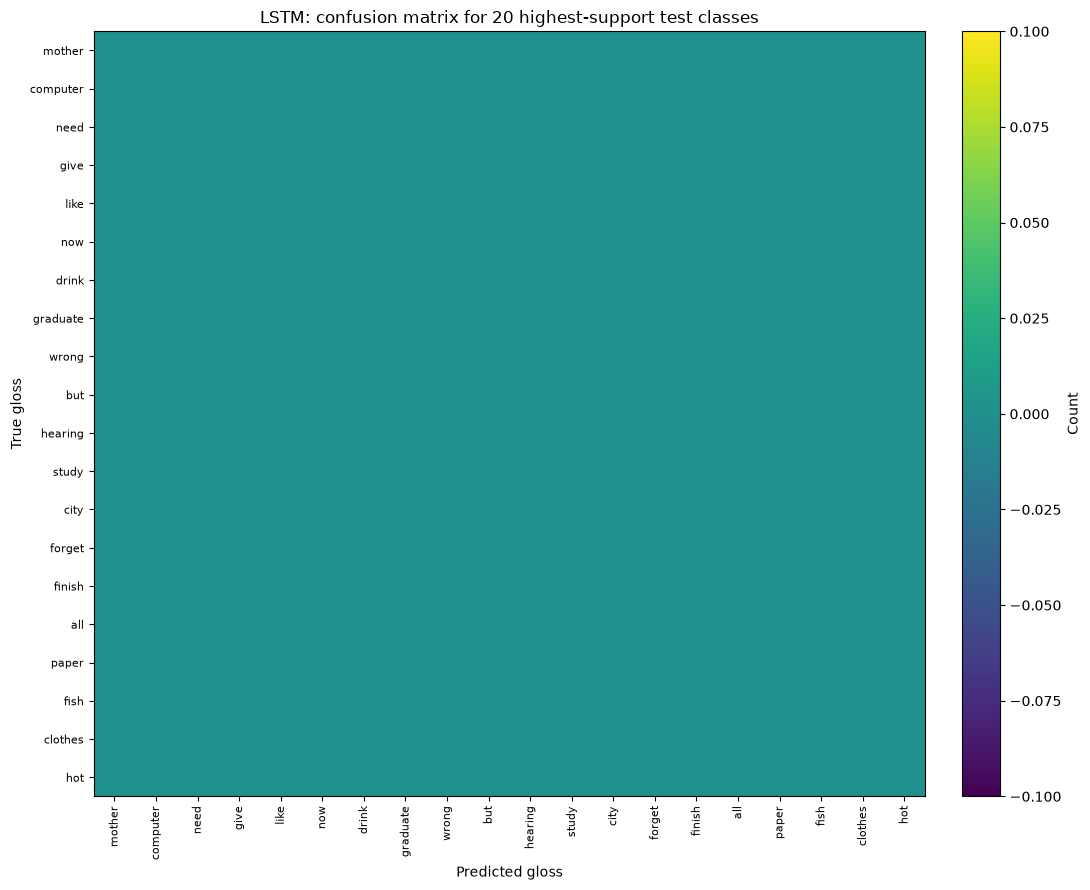

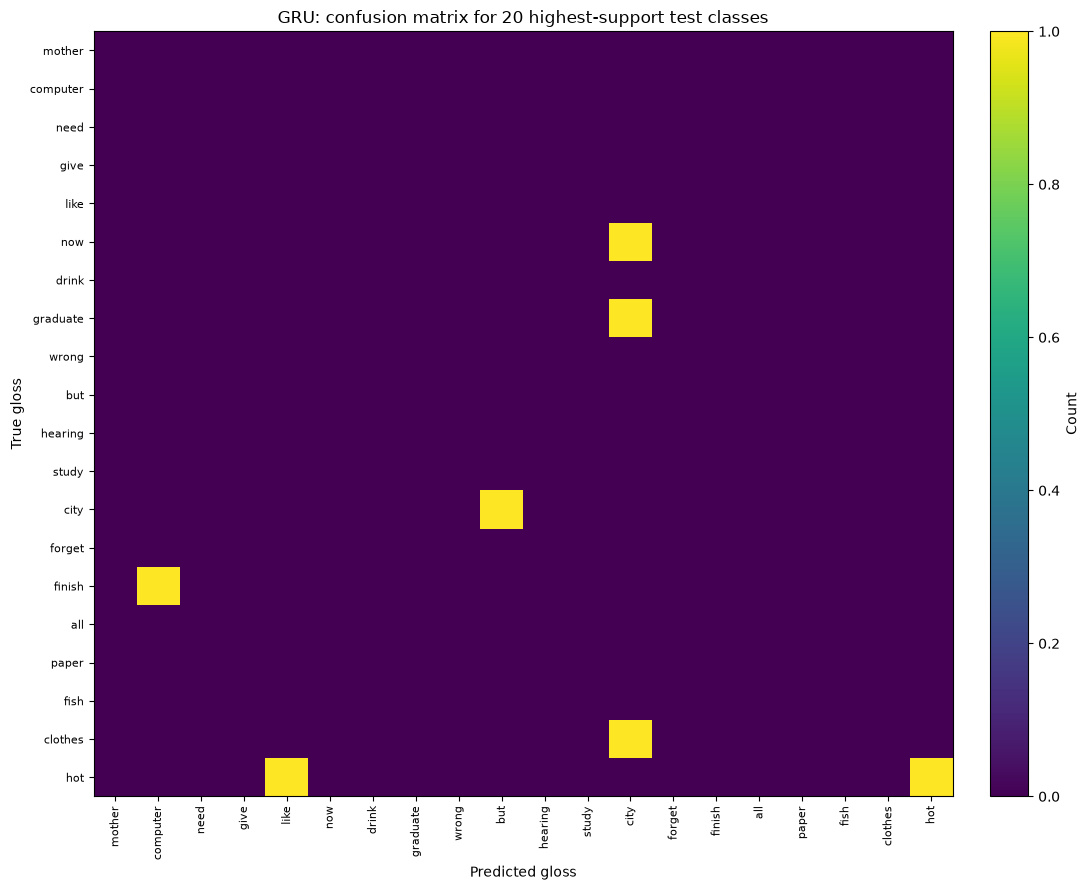

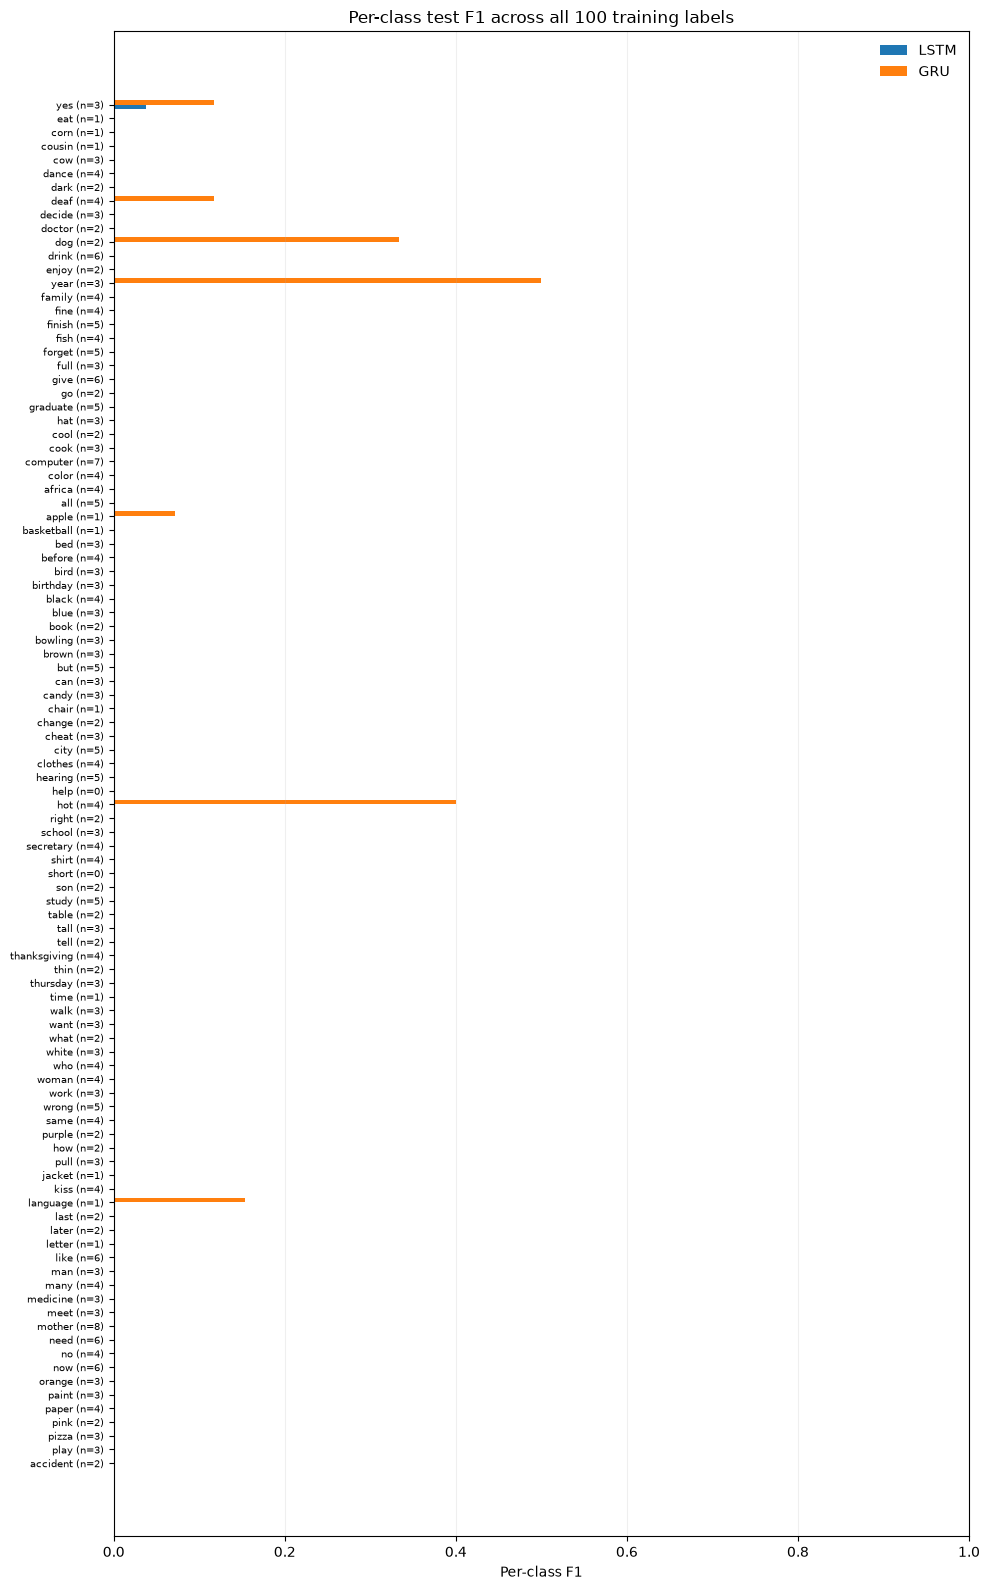

In [11]:
for name in ("LSTM", "GRU"):
    matrix = confusion_matrices[name]
    support = matrix.sum(axis=1)
    top_classes = np.argsort(support)[::-1][:20]
    fig, ax = plt.subplots(figsize=(11, 9))
    image = ax.imshow(matrix[np.ix_(top_classes, top_classes)], interpolation="nearest", aspect="auto")
    ax.set_xticks(range(len(top_classes)))
    ax.set_yticks(range(len(top_classes)))
    ax.set_xticklabels(class_names[top_classes], rotation=90, fontsize=8)
    ax.set_yticklabels(class_names[top_classes], fontsize=8)
    ax.set_xlabel("Predicted gloss")
    ax.set_ylabel("True gloss")
    ax.set_title(f"{name}: confusion matrix for 20 highest-support test classes")
    fig.colorbar(image, ax=ax, label="Count", fraction=0.046, pad=0.04)
    fig.tight_layout()
    fig.savefig(REPORT_DIR / f"{name.lower()}_confusion_top20_support.png",
                dpi=180, bbox_inches="tight")
    plt.show()

f1_pivot = per_class_df.pivot(index="gloss", columns="model", values="f1-score")
support_pivot = per_class_df.pivot(index="gloss", columns="model", values="support")
order = f1_pivot.min(axis=1).sort_values().index
fig, ax = plt.subplots(figsize=(10, 16))
y_positions = np.arange(len(order))
ax.barh(y_positions - 0.18, f1_pivot.loc[order, "LSTM"], height=0.35, label="LSTM")
ax.barh(y_positions + 0.18, f1_pivot.loc[order, "GRU"], height=0.35, label="GRU")
ax.set_yticks(y_positions)
ax.set_yticklabels([
    f"{gloss} (n={int(support_pivot.loc[gloss].max())})" for gloss in order
], fontsize=7)
ax.set_xlim(0, 1)
ax.set_xlabel("Per-class F1")
ax.set_title("Per-class test F1 across all 100 training labels")
ax.grid(axis="x", alpha=0.2)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(REPORT_DIR / "per_class_f1_all_labels.png", dpi=180, bbox_inches="tight")
plt.show()

## 13. Efficiency benchmarking

Parameter counts are exact trainable parameter counts. Model size is the serialized best-checkpoint size. Inference latency is measured as single-video latency after warm-up, using the selected device and synchronizing asynchronous MPS/CUDA execution around the timed region.

In [12]:
def benchmark_single_video(model, X, warmup=20, repeats=100):
    model.eval()
    sample = torch.from_numpy(X[:1]).to(DEVICE)
    with torch.no_grad():
        for _ in range(warmup):
            _ = model(sample)
        sync_device()
        timings = []
        for _ in range(repeats):
            sync_device()
            start = time.perf_counter()
            _ = model(sample)
            sync_device()
            timings.append(time.perf_counter() - start)
    return {
        "latency_ms_per_video_median": float(np.median(timings) * 1000),
        "latency_ms_per_video_mean": float(np.mean(timings) * 1000),
        "benchmark_batch_size": 1,
        "warmup_iterations": warmup,
        "timed_iterations": repeats,
    }

efficiency_rows = []
for name, result in experiments.items():
    latency = benchmark_single_video(result["model"], X_test)
    checkpoint_bytes = result["checkpoint_path"].stat().st_size
    efficiency_rows.append({
        "model": name,
        "device": str(DEVICE),
        "trainable_parameters": result["parameters"],
        "checkpoint_size_mb": checkpoint_bytes / (1024 ** 2),
        "training_seconds": result["training_seconds"],
        **latency,
    })

efficiency_df = pd.DataFrame(efficiency_rows)
efficiency_df.to_csv(REPORT_DIR / "efficiency.csv", index=False)
display(efficiency_df)

,model,device,trainable_parameters,checkpoint_size_mb,training_seconds,latency_ms_per_video_median,latency_ms_per_video_mean,benchmark_batch_size,warmup_iterations,timed_iterations
0,LSTM,mps,340580,1.305697,12.006231,0.931667,1.018163,1,20,100
1,GRU,mps,274532,1.053727,34.610389,4.995792,4.994738,1,20,100


## 14. Compare against Notebook 06 classical baselines

Notebook 06's saved `test_metrics_held_out.csv` is preferred and checked when present. If the report is absent, the comparison uses the executed Notebook 06 result table that accompanied this project handoff and labels that provenance explicitly. Deep-learning test results are never used to change either model.

Classical baseline provenance: Notebook 06 executed outputs supplied in project handoff


/var/folders/sv/qsh8nfp908z0x4hjly1q7tw40000gn/T/ipykernel_17953/1492381223.py:14: UserWarning: Notebook 06 report CSV was not found in this runtime. Using the verified executed Notebook 06 outputs supplied with the project notebooks.
  warnings.warn(


,model,accuracy,macro_f1_fixed_100,top5_accuracy
0,Logistic Regression,0.233438,0.209077,0.482650
1,Random Forest,0.264984,0.207826,0.533123
2,Linear SVM,0.249211,0.210917,0.454259
3,RBF SVM,0.154574,0.123605,0.391167
4,LSTM,0.009464,0.000380,0.069401
5,GRU,0.022082,0.016939,0.132492


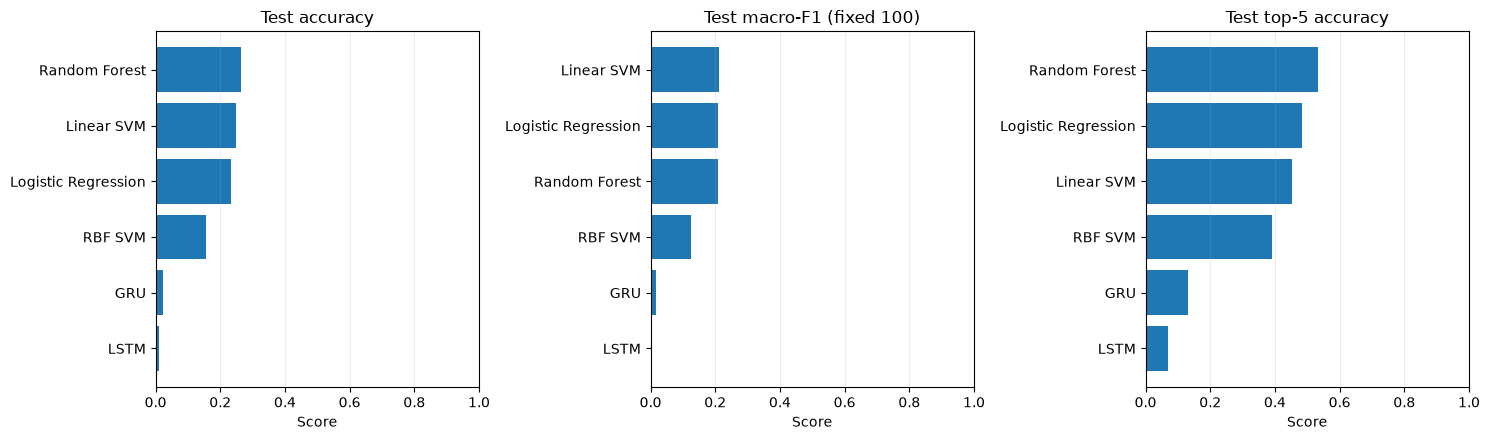

In [13]:
CLASSICAL_REPORT = ROOT / "data" / "reports" / "classical" / "v2" / "test_metrics_held_out.csv"
classical_provenance = None

if CLASSICAL_REPORT.is_file():
    classical_raw = pd.read_csv(CLASSICAL_REPORT)
    required = {"model", "accuracy", "macro_f1_train_label_set", "top5_accuracy"}
    if required - set(classical_raw.columns):
        raise ValueError(f"Classical report missing fields: {sorted(required - set(classical_raw.columns))}")
    classical = classical_raw.rename(columns={
        "macro_f1_train_label_set": "macro_f1_fixed_100"
    })
    classical_provenance = str(CLASSICAL_REPORT.relative_to(ROOT))
else:
    warnings.warn(
        "Notebook 06 report CSV was not found in this runtime. Using the verified "
        "executed Notebook 06 outputs supplied with the project notebooks."
    )
    classical = pd.DataFrame([
        {"model": "Logistic Regression", "accuracy": 0.233438,
         "macro_f1_fixed_100": 0.209077, "top5_accuracy": 0.482650},
        {"model": "Random Forest", "accuracy": 0.264984,
         "macro_f1_fixed_100": 0.207826, "top5_accuracy": 0.533123},
        {"model": "Linear SVM", "accuracy": 0.249211,
         "macro_f1_fixed_100": 0.210917, "top5_accuracy": 0.454259},
        {"model": "RBF SVM", "accuracy": 0.154574,
         "macro_f1_fixed_100": 0.123605, "top5_accuracy": 0.391167},
    ])
    classical_provenance = "Notebook 06 executed outputs supplied in project handoff"

comparison_dl = test_metrics_df[[
    "model", "accuracy", "macro_f1_fixed_100", "top5_accuracy"
]].copy()
comparison = pd.concat([classical[[
    "model", "accuracy", "macro_f1_fixed_100", "top5_accuracy"
]], comparison_dl], ignore_index=True)
comparison.to_csv(REPORT_DIR / "classical_vs_deep_learning_comparison.csv", index=False)
print("Classical baseline provenance:", classical_provenance)
display(comparison)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, metric, title in zip(
    axes,
    ["accuracy", "macro_f1_fixed_100", "top5_accuracy"],
    ["Test accuracy", "Test macro-F1 (fixed 100)", "Test top-5 accuracy"],
):
    ordered = comparison.sort_values(metric)
    ax.barh(ordered.model, ordered[metric])
    ax.set_xlim(0, 1)
    ax.set_title(title)
    ax.set_xlabel("Score")
    ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
fig.savefig(REPORT_DIR / "classical_vs_deep_learning_comparison.png",
            dpi=180, bbox_inches="tight")
plt.show()

## 15. Reproducibility record and experiment summary

The configuration, software versions, split audit, preprocessing statistics, selected epochs, metrics, model efficiency and artifact paths are saved for later analysis. The notebook does not claim that temporal modelling improves recognition unless the measured results support that conclusion.

In [14]:
experiment_config = {
    "experiment": "WLASL-100 LSTM and GRU sequence baselines",
    "feature_version": FEATURE_VERSION,
    "input": {
        "timesteps": N_STEPS,
        "channels": INPUT_DIM,
        "continuous_channels": N_CONTINUOUS,
        "mask_channels": N_MASK,
        "components": {
            "relative_coordinates": 225,
            "hand_to_body": 6,
            "hand_body_velocity": 6,
            "hand_body_acceleration": 6,
            "hand_confidence": 2,
            "continuous_channel_missingness": 245,
            "detection_masks": 5,
        },
        "imputation": "per-channel median fitted on training sequences only",
        "scaling": "none; retain Notebook 05 feature conventions",
    },
    "splits": {
        "counts": split_counts,
        "class_names": class_names.tolist(),
        "signer_counts_metadata": {k: len(v) for k, v in signer_sets.items()},
        "signer_counts_usable": {
            s: int(usable.loc[usable.experimental_split.eq(s), "signer_id"].nunique())
            for s in ("train", "val", "test")
        },
        "signer_intersections": {k: len(v) for k, v in overlaps.items()},
    },
    "model": MODEL_CONFIG,
    "training": TRAIN_CONFIG,
    "device": str(DEVICE),
    "software": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "torch": torch.__version__,
        "scikit_learn": sklearn.__version__,
    },
    "classical_baseline_source": classical_provenance,
    "test_evaluation_policy": "one final evaluation per validation-selected LSTM/GRU checkpoint; all 317 examples retained",
    "limitations": [
        "Only 1,023 of 2,038 WLASL-100 metadata instances have usable videos.",
        "Usable video coverage differs by split; the held-out test contains 317 videos.",
        "Only 50 of 97 metadata signers contribute usable videos.",
        "Landmark quality and hand detection are imperfect; missingness is represented but not recovered.",
        "MPS operations may not be bitwise deterministic across software/hardware versions.",
        "Results do not establish scalability to WLASL-300 or WLASL-2000.",
    ],
    "output_directories": {
        "models": str(MODEL_DIR.relative_to(ROOT)),
        "reports": str(REPORT_DIR.relative_to(ROOT)),
    },
}
with open(REPORT_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(experiment_config, f, indent=2)

experiment_summary = {
    "experiment": experiment_config["experiment"],
    "split_counts": split_counts,
    "device": str(DEVICE),
    "test_metrics": test_results,
    "efficiency": efficiency_df.to_dict(orient="records"),
    "training": {
        name: {
            "best_epoch": result["best_epoch"],
            "best_validation_macro_f1": result["best_validation_macro_f1"],
            "training_seconds": result["training_seconds"],
            "trainable_parameters": result["parameters"],
        }
        for name, result in experiments.items()
    },
    "comparison": comparison.to_dict(orient="records"),
    "classical_baseline_source": classical_provenance,
    "limitations": experiment_config["limitations"],
}
with open(REPORT_DIR / "experiment_summary.json", "w", encoding="utf-8") as f:
    json.dump(experiment_summary, f, indent=2)

print(json.dumps(experiment_summary, indent=2))

{
  "experiment": "WLASL-100 LSTM and GRU sequence baselines",
  "split_counts": {
    "train": 535,
    "test": 317,
    "val": 171
  },
  "device": "mps",
  "test_metrics": {
    "LSTM": {
      "accuracy": 0.00946372239747634,
      "macro_f1_fixed_100": 0.00037974683544303797,
      "macro_f1_represented": 0.00038749677086024286,
      "weighted_f1": 0.00035938186319530406,
      "top5_accuracy": 0.0694006309148265,
      "n_test_samples": 317,
      "n_test_classes_represented": 98
    },
    "GRU": {
      "accuracy": 0.022082018927444796,
      "macro_f1_fixed_100": 0.016939021762551177,
      "macro_f1_represented": 0.017284716084235895,
      "weighted_f1": 0.015190759633142264,
      "top5_accuracy": 0.13249211356466878,
      "n_test_samples": 317,
      "n_test_classes_represented": 98
    }
  },
  "efficiency": [
    {
      "model": "LSTM",
      "device": "mps",
      "trainable_parameters": 340580,
      "checkpoint_size_mb": 1.3056974411010742,
      "training_seconds"

## 16. Final integrity checks and artifact inventory

These assertions ensure that both model predictions cover all held-out examples, all confusion matrices account for 317 samples, checkpoints exist, and no upstream Notebook 01–06 output directory was targeted.

In [15]:
assert len(predictions_df) == 2 * EXPECTED_SPLIT_COUNTS["test"]
for name in ("LSTM", "GRU"):
    subset = predictions_df.loc[predictions_df.model.eq(name)]
    assert len(subset) == 317
    assert subset.video_id.nunique() == 317
    assert subset.true_gloss.notna().all()
    assert subset.predicted_gloss.notna().all()
    assert confusion_matrices[name].sum() == 317
    assert (MODEL_DIR / f"best_{name.lower()}.pt").is_file()

assert all(np.isfinite(X).all() for X in (X_train, X_val, X_test))
assert set(signer_train).isdisjoint(signer_val)
assert set(signer_train).isdisjoint(signer_test)
assert set(signer_val).isdisjoint(signer_test)

artifact_paths = sorted(
    [p for p in MODEL_DIR.glob("*") if p.is_file()]
    + [p for p in REPORT_DIR.glob("*") if p.is_file()]
)
artifact_inventory = pd.DataFrame([
    {
        "path": str(path.relative_to(ROOT)),
        "size_mb": round(path.stat().st_size / (1024 ** 2), 4),
    }
    for path in artifact_paths
])
display(artifact_inventory)
artifact_inventory.to_csv(REPORT_DIR / "artifact_inventory.csv", index=False)

print("PASS: all 317 test examples evaluated for both models.")
print("PASS: signer-independent frozen split preserved.")
print("PASS: training-only imputation; finite inputs and logits.")
print("PASS: Notebook 06 outputs were not modified.")
print(f"Models:  {MODEL_DIR}")
print(f"Reports: {REPORT_DIR}")

,path,size_mb
0,data/models/deep_learning/v1/best_gru.pt,1.0537
1,data/models/deep_learning/v1/best_lstm.pt,1.3057
2,data/reports/deep_learning/v1/classical_vs_dee...,0.0003
3,data/reports/deep_learning/v1/classical_vs_dee...,0.0544
4,data/reports/deep_learning/v1/efficiency.csv,0.0004
5,data/reports/deep_learning/v1/experiment_confi...,0.0039
6,data/reports/deep_learning/v1/experiment_summa...,0.0034
7,data/reports/deep_learning/v1/gru_confusion_ma...,0.0202
8,data/reports/deep_learning/v1/gru_confusion_ma...,0.0764
9,data/reports/deep_learning/v1/gru_confusion_to...,0.0842


PASS: all 317 test examples evaluated for both models.
PASS: signer-independent frozen split preserved.
PASS: training-only imputation; finite inputs and logits.
PASS: Notebook 06 outputs were not modified.
Models:  /Users/sahilchauhan/sign-language-recognition/data/models/deep_learning/v1
Reports: /Users/sahilchauhan/sign-language-recognition/data/reports/deep_learning/v1


## 17. Research interpretation checklist

Use the saved results to answer these questions in the subsequent diagnostic notebook:

1. Does either recurrent model outperform the strongest classical model on accuracy, fixed-100 macro-F1 or top-5?
2. Is any apparent accuracy gain accompanied by a macro-F1 gain, or does it mainly benefit frequent classes?
3. Do LSTM and GRU show different validation-to-test generalization gaps?
4. Are the weakest classes associated with sparse training support or poor landmark detection?
5. Is the gain, if any, worth the additional training and inference cost?

**Do not infer that deep learning is inherently better from architecture alone.** The usable training set contains only 535 videos across 100 classes, and only 50 signers contribute usable examples. A modest or negative result is still a valid finding for this experimental setting.

## References

- Li, D., Rodriguez, C., Yu, X., & Li, H. (2020). *Word-level Deep Sign Language Recognition from Video: A New Large-scale Dataset and Methods Comparison*. WACV.
- Hochreiter, S., & Schmidhuber, J. (1997). Long Short-Term Memory. *Neural Computation*, 9(8), 1735–1780.
- Cho, K. et al. (2014). Learning Phrase Representations using RNN Encoder–Decoder for Statistical Machine Translation. *EMNLP*.